# VAR model for vitals


In [36]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller
from statsmodels.tools.eval_measures import rmse, aic
from statsmodels.tsa.stattools import grangercausalitytests
from statsmodels.tsa.vector_ar.vecm import coint_johansen
from statsmodels.stats.stattools import durbin_watson


In [2]:
df_vitals = pd.read_csv('vitals_combined_interpolated.csv')
df_beta = pd.read_csv('beta-blocker-dosages.csv')

In [3]:
df_vitals.columns = ['patient_uuid', 'timestamp', 'batch', 'HR', 'SBP']

In [4]:
df_vitals.head()

,patient_uuid,timestamp,batch,HR,SBP
0,1127912,2019-11-19,0,87.261064,124.85394
1,1127912,2019-11-20,0,92.000000,120.50000
2,1127912,2019-11-21,0,87.000000,131.75000
3,1127912,2019-11-22,0,89.000000,127.00000
4,1127912,2019-11-23,0,93.000000,109.50000


In [5]:
df_vitals['timestamp'] = pd.to_datetime(df_vitals['timestamp'], errors='coerce')

df_vitals = df_vitals[['patient_uuid', 'timestamp', 'batch', 'HR', 'SBP']]

df_vitals = df_vitals[(df_vitals.timestamp >= '2018-10-01') & (df_vitals.timestamp <= '2020-01-14')]
df_vitals = df_vitals[~df_vitals['SBP'].isna()]
df_vitals = df_vitals[~df_vitals['HR'].isna()]

# columns with number of non-empty rows
(~df_vitals.isna()).sum() / len(df_vitals) * 100

patient_uuid    100.0
timestamp       100.0
batch           100.0
HR              100.0
SBP             100.0
dtype: float64

In [6]:
# Drops batches containing less than 30 observations.
df_recordings_per_patient = df_vitals.groupby(['patient_uuid', 'batch']).count().reset_index()
low_batches = df_recordings_per_patient[(df_recordings_per_patient.HR <= 30)][['patient_uuid','batch']]

for i in range(len(low_batches)):
    low_patient = low_batches.patient_uuid.iloc[i]
    low_batch = low_batches.batch.iloc[i]
    df_vitals.drop(df_vitals[(df_vitals.patient_uuid == low_patient) & (df_vitals.batch == low_batch)].index, inplace=True)
    
idx = df_vitals.groupby(['patient_uuid'])['batch'].transform(max) == df_vitals['batch']
df_vitals = df_vitals[idx]

In [7]:
# Creates patient list based on the cleaned dataframe.
patients = df_vitals.patient_uuid.unique()

In [8]:
def grangers_causation_matrix(data, variables, test='ssr_chi2test', verbose=False):    
    """
    Check Granger Causality of all possible combinations of the Time series.
    The rows are the response variable, columns are predictors. The values in the table 
    are the P-Values. P-Values lesser than the significance level (0.05), implies 
    the Null Hypothesis that the coefficients of the corresponding past values is 
    zero, that is, the X does not cause Y can be rejected.

    data     : pandas dataframe containing the time series variables
    variables: list containing names of the time series variables.
    
    output   : dataframe containing p-values to test causation.
    """
    maxlag = 9
    test = 'ssr_chi2test'
    
    df = pd.DataFrame(np.zeros((len(variables), len(variables))), columns=variables, index=variables)
    for c in df.columns:
        for r in df.index:
            test_result = grangercausalitytests(data[[r, c]], maxlag=maxlag, verbose=False)
            p_values = [round(test_result[i+1][0][test][1],4) for i in range(maxlag)]
            if verbose: print(f'Y = {r}, X = {c}, P Values = {p_values}')
            min_p_value = np.min(p_values)
            df.loc[r, c] = min_p_value
    df.columns = [var + '_x' for var in variables]
    df.index = [var + '_y' for var in variables]
    return df



In [9]:
def cointegration_test(df, alpha=0.05): 
    """
    Perform Johansen's Cointegration Test and Report Summary.
    
    df    : time series dataframe for a particular patient.
    
    output: prints summary of the results of the cointegration test.
    """
    out = coint_johansen(df,-1,5)
    d = {'0.90':0, '0.95':1, '0.99':2}
    traces = out.lr1
    cvts = out.cvt[:, d[str(1-alpha)]]
    def adjust(val, length= 6): return str(val).ljust(length)

    # Summary
    print('Name   ::  Test Stat > C(95%)    =>   Signif  \n', '--'*20)
    for col, trace, cvt in zip(df.columns, traces, cvts):
        print(adjust(col), ':: ', adjust(round(trace,2), 9), ">", adjust(cvt, 8), ' =>  ' , trace > cvt)

In [10]:
def cointest2(df, alpha=0.05):
    """
    Perform Johansen's Cointegration Test.
    
    df    : time series dataframe for a particular patient.

    output: returns boolean values for each column.
    """
    out = coint_johansen(df,-1,7)
    
    bool_list = []
    for i in range(len(df.columns)):
        bool_list.append(out.lr1[i] > out.cvt[:,1][i])
    
    return bool_list

In [11]:
def adfuller_test(series, signif=0.05, name='', verbose=False):
    """
    Performs ADFuller to test for Stationarity of given series and prints report.
    
    series: pandas series of the feature to test stationarity on.
    
    output: True if stationary, False if not stationary.
    
    """
    r = adfuller(series, autolag='AIC')
    p_value = round(r[1], 4)

    if p_value <= signif:
        is_stationary = True
    else:
        is_stationary = False
        
    return is_stationary

In [12]:
def test_var(patient):
    """
    Performs Granger's Causality Test, Johansen's Cointegration Test, ADFuller Test,
    and Durbin Watson Statistic Test on the time series of the selected patient.
    
    patient: integer corresponding to a patient id, patient_uuid.
    
    output : list containing results for each test.
             SBP_x    : p-value of interaction between SBP as independent variable 
                        and HR as response variable.
             SBP_y    : p-value of interaction between SBP as response variable 
                        and HR as independent variable.
             coint_HR : boolean indicating if HR is cointegrated.
             coint_SBP: boolean indicating if SBP is cointegrated.
             diff     : number of differentiation needed for both variables
                        to be stationary.
             dw_HR    : serial correlation of residuals of HR.
             dw_SBP   : serial correlation of residuals of SBP.
    """
    nobs = 7
    diff = 0
    max_diff = 2
    
    df_patient = df_vitals[df_vitals.patient_uuid == patient]
    
    df_patient.index = pd.DatetimeIndex(df_patient.timestamp).to_period('D')
    df_patient = df_patient[['HR','SBP']].copy()

    
    SBP_x = grangers_causation_matrix(df_patient, variables = df_patient.columns).iloc[0][1]
    SBP_y = grangers_causation_matrix(df_patient, variables = df_patient.columns).iloc[1][0]
    
    
    coint_HR, coint_SBP = cointest2(df_patient)
    
    
    df_train, df_test = df_patient[0:-nobs], df_patient[-nobs:]
    df_train2 = df_train.copy()
    

    are_stationary = []
    for name, column in df_train.iteritems():
        are_stationary.append(adfuller_test(column, name=column.name))
        
    while (all(are_stationary) == False) and (diff < max_diff):
        are_stationary = []
        df_train = df_train.diff().dropna()
        df_patient = df_patient.diff().dropna()
        for name, column in df_train.iteritems():
            are_stationary.append(adfuller_test(column, name=column.name))

        diff += 1

    
    model = VAR(df_train)
    lag_order = 7 #model.select_order(maxlags=20).aic
    if lag_order == 0:
        lag_order = 7
    model_fitted = model.fit(lag_order)
    
    
    dw_HR, dw_SBP = durbin_watson(model_fitted.resid)
    
    return [SBP_x, SBP_y, coint_HR, coint_SBP, diff, dw_HR, dw_SBP]

In [13]:
def invert_transformation(df_train, df_forecast, second_diff=False):
    """
    Revert back the differencing to get the forecast to original scale.
    
    df_train   : training set of the timeseries for a particular patient.
    df_forecast: forecast of the timeseries for a particular patient.
    
    output     : forecast dataframe with its values converted to its original scale.
    """
    df_fc = df_forecast.copy()
    columns = df_train.columns
    for col in columns:        
        # Roll back 2nd Diff
        if second_diff:
            df_fc[str(col) + '_forecast'] = (df_train[col].iloc[-1]-df_train[col].iloc[-2]) + df_fc[str(col)+'_forecast'].cumsum()
        # Roll back 1st Diff
        df_fc[str(col) + '_forecast'] = df_train[col].iloc[-1] + df_fc[str(col)+'_forecast'].cumsum()
    return df_fc

In [14]:
def forecast_accuracy(forecast, actual):
    """
    Calculates accuracy by calculating mean absolute percentage error, mean absolute error, 
    and root-mean-squared error.
    
    forecast: forecast dataframe containing the results from a model.
    actual  : test set of a particular patient, with same dates as the forecast dataframe.
    
    output  : mape: mean absolute percentage error
              mae : mean absolute error
              rsme: root mean square error
    """
    forecast = forecast.values
    mape = np.mean(np.abs(forecast - actual)/np.abs(actual))  # MAPE
    mae = np.mean(np.abs(forecast - actual))    # MAE
    rmse = np.mean((forecast - actual)**2)**.5  # RMSE
    return mape, mae, rmse

In [15]:
def var_model(patient):
    """
    Creates train and test sets for a particular patient, runs adfuller test to check stationarity, 
    differentiates dataframe if not stationary, fits model, and creates a forecast (to compare with test set), 
    and a future dataframe containing the predicted values for the dates following the test set.
    
    patient: patient uuid
    
    output : df_train2  : copy of the training set for a particular patient.
             df_test    : test set for a particular patient.
             df_forecast: forecasted values to compare with test set.
             df_future  : predicted values for future dates.
    """
    nobs = 7
    diff = 0
    max_diff = 2
    
    df_patient = df_vitals[df_vitals.patient_uuid == patient]
    
    df_patient.index = pd.DatetimeIndex(df_patient.timestamp).to_period('D')
    df_patient = df_patient[['HR','SBP']].copy()
    df_patient2 = df_patient.copy()
    
    df_train, df_test = df_patient[0:-nobs], df_patient[-nobs:]
    df_train2 = df_train.copy()
    

    are_stationary = []
    for name, column in df_train.iteritems():
        are_stationary.append(adfuller_test(column, name=column.name))
        
    while (all(are_stationary) == False) and (diff < max_diff):
        are_stationary = []
        df_train = df_train.diff().dropna()
        df_patient = df_patient.diff().dropna()
        for name, column in df_train.iteritems():
            are_stationary.append(adfuller_test(column, name=column.name))

        diff += 1

    model = VAR(df_train)
    lag_order = 7 #model.select_order(maxlags=20).aic

    model_fitted = model.fit(lag_order)
    forecast_input = df_train.values[-lag_order:]
    future_input = df_patient.values[-lag_order:]
    
    fc = model_fitted.forecast(y=forecast_input, steps=nobs)
    fc2 = model_fitted.forecast(y=future_input, steps=nobs)
    
    df_forecast = pd.DataFrame(fc, index=df_patient.index[-nobs:], columns=df_patient.columns + '_forecast')
    df_future = pd.DataFrame(fc2, index=df_patient[-nobs:].index + 7, columns = df_patient.columns + '_forecast')
    
    if diff == 1:
        df_forecast = invert_transformation(df_train2, df_forecast, second_diff=False)
        df_future = invert_transformation(df_patient2, df_future, second_diff=False)
    elif diff == 2:
        df_forecast = invert_transformation(df_train2, df_forecast, second_diff=True)
        df_future = invert_transformation(df_patient2, df_future, second_diff=True)
        
    return  df_train2, df_test, df_forecast, df_future

In [16]:
# Runs VAR model on all patients and collects data on accuracy.
HR_mape = []
HR_mae = []
HR_rsme = []
SBP_mape = []
SBP_mae = []
SBP_rsme = []

for patient in patients:
    results_train, results_test, results_forecast, results_future = var_model(patient)
    accuracy_indicators = forecast_accuracy(results_forecast, results_test)
    
    HR_mape.append(accuracy_indicators[0][0])
    HR_mae.append(accuracy_indicators[1][0])
    HR_rsme.append(accuracy_indicators[2][0])
    SBP_mape.append(accuracy_indicators[0][1])
    SBP_mae.append(accuracy_indicators[1][1])
    SBP_rsme.append(accuracy_indicators[2][1])

/home/ablew/anaconda3/lib/python3.7/site-packages/statsmodels/tsa/vector_ar/var_model.py:707: RuntimeWarning: divide by zero encountered in true_divide
  omega = sse / df_resid


In [17]:
# Creates and populates dataframe containing data on accuracy of the models for each patient.
df_model = pd.DataFrame(columns = ['patient_uuid', 'HR_mape', 'HR_mae', 'HR_rsme', 'SBP_mape', 'SBP_mae', 'SBP_rsme'])
df_model.patient_uuid = patients
df_model.HR_mape = HR_mape
df_model.HR_mae = HR_mae
df_model.HR_rsme = HR_rsme
df_model.SBP_mape = SBP_mape
df_model.SBP_mae = SBP_mae
df_model.SBP_rsme = SBP_rsme

df_model.head()

,patient_uuid,HR_mape,HR_mae,HR_rsme,SBP_mape,SBP_mae,SBP_rsme
0,1127912,0.056662,5.166311,6.590516,0.042878,5.674134,6.527898
1,1164638,0.015971,1.250469,1.912734,0.016423,1.935242,3.428934
2,1166047,0.114683,7.911892,8.068932,0.126569,14.273312,15.166446
3,1193821,0.029995,1.925800,2.473920,0.103789,11.870040,13.675413
4,1231804,0.065583,5.092933,5.246183,0.126942,14.963018,18.015287


In [18]:
df_model.to_csv('models_stats.csv', index=False)

### Flag-raising algorithm

In [19]:
def flags(df, report=False):
    """
    Flag-raising algorithm based on health deterioration rules.
    
    df    : 30-day timeseries pandas dataframe.
    report: True if written report requested. False if status of each flag is wanted.
    
    output: returns a list containing the average value of HR and SBP during the last ten days of the time series,
            and the different flags that are raised based on the conditions above.
    """
    rising_HR = False
    lowering_HR = False
    rising_SBP = False
    high_BP = False
    
    first_ten = np.mean(df[:10])
    last_ten = np.mean(df[-10:])

    deltas = (last_ten - first_ten)
    
    if deltas[0] >= 10:
        rising_HR = True
        flag_message_1 = 'Detected rising heart rate. \n'
    elif deltas[0] <= -10:
        lowering_HR = True
        flag_message_1 = 'Detected decreasing heart rate. \n'
    else:
        flag_message_1 = 'No changes in heart rate detected. \n'
        
    if deltas[1] >= 5:
        rising_SBP = True
        flag_message_2 = 'Detected rising blood pressure (SBP). \n'
    else:
        flag_message_2 = 'No changes in blood pressure detected. \n'

    min_HR = np.sum(df.HR < 55)
    max_HR = np.sum(df.HR > 100)

    min_SBP = np.sum(df.SBP < 90)
    max_SBP = np.sum(df.SBP > 180)
    
    flag_message_3 = 'Heart rate lower than 55 bpm detected ' + str(min_HR) + ' times. \n'
    flag_message_4 = 'Heart rate greater than 100 bpm detected ' + str(max_HR) + ' times. \n'
    flag_message_5 = 'Systolic blood pressure (SBP) lower than 90 bpm detected ' + str(min_SBP) + ' times. \n'
    flag_message_6 = 'Systolic blood pressure (SBP) greater than 180 bpm detected ' + str(max_SBP) + ' times. \n'
    flag_message_7 = ''
    
    high_SBP = (df.SBP > 140)
    
    if np.sum(high_SBP[-7:]) > 3:
        high_BP = True
        flag_message_7 = 'High blood pressure detected.'
    if report == True:
        if high_BP == True:
            message = flag_message_1 + flag_message_2 + flag_message_3 + flag_message_4 + flag_message_5 + flag_message_6 + flag_message_7 
        else:
            message = flag_message_1 + flag_message_2 + flag_message_3 + flag_message_4 + flag_message_5 + flag_message_6
        print(message)
    else:
        return [last_ten, rising_HR, lowering_HR, rising_SBP, min_HR, max_HR, min_SBP, max_SBP, high_BP]

In [66]:
def compare_flags(df_train, df_test, df_forecast):
    """
    Compares the results of the flag-raising algorithm.
    
    df_train   : training set of the timeseries for a particular patient.
    df_test    : test set of the timeseries for a particular patient.
    df_forecast: forecast of the timeseries for a particular patient.
    
    output     : list containing HR_error, SBP_error, algorithm accuracy, 
                 predicted flags and actual flags.
    """
    flag_comparison = []
    current = df_train[['HR','SBP']][-23:].copy()
    future = df_test[['HR','SBP']].copy()
    forecast = df_forecast.copy()
    forecast.columns = ['HR', 'SBP']
    actual = pd.concat([current, future])
    pred = pd.concat([current, forecast])
    
    actual_flags = flags(actual)
    pred_flags = flags(pred)
    
    HR_error = (np.abs(df_forecast.HR_forecast - df_test.HR) / df_test.HR).mean()
    SBP_error = (np.abs(df_forecast.SBP_forecast - df_test.SBP) / df_test.SBP).mean()

    for i in range(len(actual_flags)):
        flag_comparison.append(actual_flags[i] == pred_flags[i])
    
    algo_accuracy = np.sum(flag_comparison[1:]) / 8
    
    result = [HR_error, SBP_error, algo_accuracy] + actual_flags[1:] + pred_flags[1:]
    
    return result


In [67]:
# Defines column names for dataframe
flag_columns = ['patient_uuid', 'HR_error', 'SBP_error', 'algo_accuracy', 'actual_rising_HR', 'actual_lowering_HR',
                'actual_rising_SBP', 'actual_min_HR', 'actual_max_HR', 'actual_min_SBP', 'actual_max_SBP', 'actual_high_BP',
                'pred_rising_HR', 'pred_lowering_HR', 'pred_rising_SBP', 'pred_min_HR', 'pred_max_HR', 'pred_min_SBP',
                'pred_max_SBP', 'pred_high_BP']

In [68]:
# Creates and populates dataframe based on how the flag-raising algorithm performed against the test and forecast sets.
data = []
for patient in patients:
    df_train, df_test, df_forecast, df_future = var_model(patient)
    flag_row = compare_flags(df_train, df_test, df_forecast)
    flag_row = [patient] + flag_row
    data.append(flag_row)
df_flags = pd.DataFrame(data, columns=flag_columns)

In [69]:
# Rearranges the columns to allow comparisons between actual and predicted flags.
df_flags = df_flags[['patient_uuid', 'HR_error', 'SBP_error', 'algo_accuracy', 'pred_rising_HR', 'actual_rising_HR',
                     'pred_lowering_HR', 'actual_lowering_HR', 'pred_rising_SBP', 'actual_rising_SBP', 'pred_high_BP',
                     'actual_high_BP', 'pred_min_HR', 'actual_min_HR', 'pred_max_HR', 'actual_max_HR', 'pred_min_SBP', 
                     'actual_min_SBP', 'pred_max_SBP', 'actual_max_SBP']]

In [70]:
df_flags.head()

,patient_uuid,HR_error,SBP_error,algo_accuracy,pred_rising_HR,actual_rising_HR,pred_lowering_HR,actual_lowering_HR,pred_rising_SBP,actual_rising_SBP,pred_high_BP,actual_high_BP,pred_min_HR,actual_min_HR,pred_max_HR,actual_max_HR,pred_min_SBP,actual_min_SBP,pred_max_SBP,actual_max_SBP
0,1127912,0.056662,0.042878,0.875,False,False,False,False,False,False,False,False,0,0,0,1,0,0,0,0
1,1164638,0.015971,0.016423,1.000,False,False,False,False,False,False,False,False,0,0,0,0,0,0,0,0
2,1166047,0.114683,0.126569,0.875,False,False,False,False,False,False,False,False,0,0,0,0,1,0,0,0
3,1193821,0.029995,0.103789,0.875,False,False,False,False,True,False,False,False,0,0,0,0,0,0,0,0
4,1231804,0.065583,0.126942,1.000,False,False,False,False,True,True,False,False,0,0,0,0,9,9,0,0


In [26]:
df_flags.to_csv('flag_stats.csv', index=False)

# Model and Flag Metrics

### Model metrics

In [28]:
# Removing patients due to errors in overwritten data.
d_patients = list(df_model[df_model.HR_mape > 1].patient_uuid)
d_patients2 = list(df_flags[df_flags.SBP_error == 0].patient_uuid.unique())
d_patients3 = list(df_flags[df_flags.HR_error == 0].patient_uuid.unique())
d_patients = list(pd.Series(d_patients + d_patients2 + d_patients3).unique())
r_patients = df_model[~df_model.patient_uuid.isin(d_patients)].patient_uuid.unique()

df_model = df_model[df_model.patient_uuid.isin(r_patients)]
df_flags = df_flags[df_flags.patient_uuid.isin(r_patients)]

In [29]:
# Creates dataframe containing mape, mae, and rsme values for each model.
var_metrics = np.round(df_model[['HR_mape', 'HR_mae', 'HR_rsme', 'SBP_mape','SBP_mae','SBP_rsme']].mean(), 2)
sarima_metrics = [0.05, 6.13, 7.75, 0.05, 3.56, 4.58]
lstm_metrics = [0.03, 4.40, 5.47, 0.03, 2.57, 3.21]
model_metrics = pd.DataFrame(var_metrics, columns=['VAR'])
model_metrics['SARIMA'] = sarima_metrics
model_metrics['LSTM'] = lstm_metrics
model_metrics = model_metrics[['LSTM', 'VAR', 'SARIMA']]
model_metrics

,LSTM,VAR,SARIMA
HR_mape,0.03,0.04,0.05
HR_mae,4.40,3.22,6.13
HR_rsme,5.47,4.05,7.75
SBP_mape,0.03,0.05,0.05
SBP_mae,2.57,5.96,3.56
SBP_rsme,3.21,7.48,4.58


### Flag metrics

In [38]:
def accuracy_f1(true_positive, true_negative, false_positive, false_negative):
    """
    Calculates accuracy and F1-score for a particular feature.
    
    true_positive : number of true positives.
    true_negative : number of true negatives.
    false_positive: number of false positives.
    false_negative: number of false negatives.
    
    output:    acc: accuracy of the model on the feature.
          f1_score: F1-score of the model on the feature.
    """
    acc = (true_positive + true_negative) / (true_positive + false_positive + false_negative + true_negative)
    prec = true_positive / (true_positive + false_positive)
    rec = true_positive / (true_positive + false_negative)
    f1_score = 2 * (rec * prec) / (rec + prec)
    if (rec == 0) & (prec == 0):
        f1_score = 0
    return acc, f1_score

In [30]:
# Calculates accuracy and F1-scores for binary flags, and mae for numerical flags.
# rising hr
tp_rising_HR = np.sum((df_flags.pred_rising_HR == True) & (df_flags.actual_rising_HR == True))
tn_rising_HR = np.sum((df_flags.pred_rising_HR == False) & (df_flags.actual_rising_HR == False))
fp_rising_HR = np.sum((df_flags.pred_rising_HR == True) & (df_flags.actual_rising_HR == False))
fn_rising_HR = np.sum((df_flags.pred_rising_HR == False) & (df_flags.actual_rising_HR == True))

# lowering hr
tp_lowering_HR = np.sum((df_flags.pred_lowering_HR == True) & (df_flags.actual_lowering_HR == True))
tn_lowering_HR = np.sum((df_flags.pred_lowering_HR == False) & (df_flags.actual_lowering_HR == False))
fp_lowering_HR = np.sum((df_flags.pred_lowering_HR == True) & (df_flags.actual_lowering_HR == False))
fn_lowering_HR = np.sum((df_flags.pred_lowering_HR == False) & (df_flags.actual_lowering_HR == True))

# rising sbp
tp_rising_SBP = np.sum((df_flags.pred_rising_SBP == True) & (df_flags.actual_rising_SBP == True))
tn_rising_SBP = np.sum((df_flags.pred_rising_SBP == False) & (df_flags.actual_rising_SBP == False))
fp_rising_SBP = np.sum((df_flags.pred_rising_SBP == True) & (df_flags.actual_rising_SBP == False))
fn_rising_SBP = np.sum((df_flags.pred_rising_SBP == False) & (df_flags.actual_rising_SBP == True))

# high_bp
tp_high_BP = np.sum((df_flags.pred_high_BP == True) & (df_flags.actual_high_BP == True))
tn_high_BP = np.sum((df_flags.pred_high_BP == False) & (df_flags.actual_high_BP == False))
fp_high_BP = np.sum((df_flags.pred_high_BP == True) & (df_flags.actual_high_BP == False))
fn_high_BP = np.sum((df_flags.pred_high_BP == False) & (df_flags.actual_high_BP == True))

# metrics for binary flags
acc_rising_HR, f1_rising_HR = accuracy_f1(tp_rising_HR, tn_rising_HR, fp_rising_HR, fn_rising_HR)
acc_lowering_HR, f1_lowering_HR = accuracy_f1(tp_lowering_HR, tn_lowering_HR, fp_lowering_HR, fn_lowering_HR)
acc_rising_SBP, f1_rising_SBP = accuracy_f1(tp_rising_SBP, tn_rising_SBP, fp_rising_SBP, fn_rising_SBP)
acc_high_BP, f1_high_BP = accuracy_f1(tp_high_BP, tn_high_BP, fp_high_BP, fn_high_BP)

# mae for numerical flags
mae_min_HR = np.abs(df_flags.pred_min_HR - df_flags.actual_min_HR).mean()
mae_max_HR = np.abs(df_flags.pred_max_HR - df_flags.actual_max_HR).mean()
mae_min_SBP = np.abs(df_flags.pred_min_SBP - df_flags.actual_min_SBP).mean()
mae_max_SBP = np.abs(df_flags.pred_max_SBP - df_flags.actual_max_SBP).mean()

In [61]:
# Creates dataframe containing the performance indicators of the three models for the flag-raising algorithm.

algo_metrics = [acc_rising_HR, f1_rising_HR, acc_lowering_HR, f1_lowering_HR, acc_rising_SBP, f1_rising_SBP,
                acc_high_BP, f1_high_BP, mae_min_HR, mae_max_HR, mae_min_SBP, mae_max_SBP]

algo_metrics_index = ['acc_rising_HR', 'f1_rising_HR', 'acc_lowering_HR', 'f1_lowering_HR', 'acc_rising_SBP',
                      'f1_rising_SBP','acc_high_BP', 'f1_high_BP', 'mae_min_HR', 'mae_max_HR', 'mae_min_SBP',
                      'mae_max_SBP']

df_algo = pd.DataFrame(algo_metrics, index=algo_metrics_index, columns=['VAR'])
df_algo.index.name = 'Flags'
df_algo['LSTM'] = [0.01698754246885617, 0.011389521640091117, 0.9818799546998868, 0, 0.8912797281993206, 
                   0.02040816326530612, 0.7746319365798414, 0, 0.2650056625141563, 6.805209513023782,
                   6.498301245753114, 0.022650056625141562]
df_algo['SARIMA'] = [0.016042780748663103, 0.008086253369272236, 0.983957219251337, 0, 0.8890374331550802, 0,
                     0.7847593582887701, 0, 0.2606951871657754, 6.711229946524064, 6.3810160427807485, 0.02807486631016043]
df_algo = df_algo[['LSTM', 'VAR', 'SARIMA']]
df_algo = np.round(df_algo, 2)
df_algo

,LSTM,VAR,SARIMA
Flags,,,
acc_rising_HR,0.02,0.99,0.02
f1_rising_HR,0.01,0.50,0.01
acc_lowering_HR,0.98,0.99,0.98
f1_lowering_HR,0.00,0.67,0.00
acc_rising_SBP,0.89,0.91,0.89
f1_rising_SBP,0.02,0.57,0.00
acc_high_BP,0.77,0.93,0.78
f1_high_BP,0.00,0.84,0.00
mae_min_HR,0.27,0.15,0.26


## Test Metrics

In [37]:
# Creates dataframe containing the results of the different tests used for VAR.
test_data = []
for patient in r_patients:
    test_results = [patient] + test_var(patient)
    test_data.append(test_results)
df_test_metrics = pd.DataFrame(test_data, columns=['patient_uuid', 'SBP_x', 'SBP_y', 'coint_HR', 'coint_SBP', 'diff', 'dw_HR', 'dw_SBP'])
df_test_metrics.head()

,patient_uuid,SBP_x,SBP_y,coint_HR,coint_SBP,diff,dw_HR,dw_SBP
0,1127912,0.0028,0.0002,False,False,1,1.987048,1.834407
1,1164638,0.0000,0.0002,False,False,1,1.980878,2.069782
2,1166047,0.0032,0.0003,True,True,2,2.034221,2.133801
3,1193821,0.0842,0.1259,True,False,0,1.972000,2.005288
4,1231804,0.7281,0.6350,False,False,0,1.949132,2.001980


In [52]:
# Proportion of patients showing p-values less than 0.05 for Granger's Causality Test.
prop_SBP_x = np.round(len(df_test_metrics[df_test_metrics.SBP_x < 0.05]) / len(df_test_metrics), 4)
prop_SBP_y = np.round(len(df_test_metrics[df_test_metrics.SBP_y < 0.05]) / len(df_test_metrics), 4)

prop_SBP_x, prop_SBP_y

(0.6103, 0.6185)

In [53]:
# Mean aggregation of the binary results of the cointegration test.
agg_coint_HR = np.mean(df_test_metrics.coint_HR)
agg_coint_SBP = np.mean(df_test_metrics.coint_SBP)

agg_coint_HR, agg_coint_SBP

(0.42370892018779344, 0.01995305164319249)

In [56]:
# Proportion of the number of differentations required to show stationarity.
df_test_metrics['diff'].value_counts() / len(df_test_metrics)

0    0.566901
1    0.393192
2    0.039906
Name: diff, dtype: float64

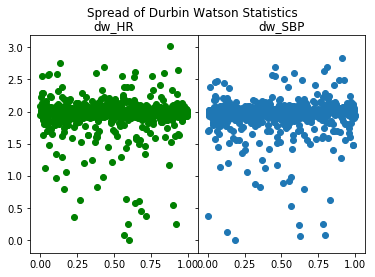

In [48]:
# Creates a plot showing the spread of the results of the Durbin Watson Statistic.
# The x-axis is randomized in order to convert the data from 1-d to 2-d.
fig, axs = plt.subplots(1, 2, sharex='col', sharey='row',
                        gridspec_kw={'hspace': 0, 'wspace': 0})
(ax1, ax2) = axs
fig.suptitle("Spread of Durbin Watson Statistics")
ax1.scatter(np.random.rand(len(df_test_metrics.dw_HR)), df_test_metrics.dw_HR, color='g')
ax1.set_title('dw_HR')
ax2.scatter(np.random.rand(len(df_test_metrics.dw_SBP)), df_test_metrics.dw_SBP)
ax2.set_title('dw_SBP')
for ax in axs.flat:
    ax.label_outer()

In [59]:
# Proportion of patients showing output values between 1.75 and 2.25
prop_dw_HR = np.round(len(df_test_metrics[(df_test_metrics.dw_HR < 2.25) & (df_test_metrics.dw_HR > 1.75)]) / len(df_test_metrics), 4)
prop_dw_SBP = np.round(len(df_test_metrics[(df_test_metrics.dw_SBP < 2.25) & (df_test_metrics.dw_SBP > 1.75)]) / len(df_test_metrics), 4)

prop_dw_HR, prop_dw_SBP

(0.8932, 0.8885)